# TP2

## Extraire les mots clés de tous les documemts CAMille de 1920 avec Yake

## Imports

In [5]:
import os
import yake

In [6]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

https://github.com/INESCTEC/yake

In [7]:
# Choisir une année
year = 1920 # année des jeux olympiques à Anvers

In [8]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

101

In [9]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [10]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

101

In [27]:
for f in sorted(txts)[:10]:
    text = open(os.path.join(txt_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) >= 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB427_1920-01-10_01-00004.txt mentions these keywords: bureau du journal, erdu malle, Bonne fabrique demande, bonne réeom, bons gages, places BUT demande, bureau journal, lee bons, référ. exig, rue Jacques Jor, VENTE PUBLIQUE...
KB_JB838_1920-01-13_01-00005.txt mentions these keywords: Wnrt Itft mmm, Itft mmm aoi, Wnrt Itft, louer maison, Itft mmm, louer petite maison, BOULANGER afrnUmk, louer maison bourgeoise, oriSilrii louer maison, jnrntUi chaud, mmm aoi, DÉSIRE LOUER, Farte Maison Fronçait, VENDRE maison, désire louer Centre, LOUER bon, louer mal, LOUER bel, belle maison, FUS MAITRES-CHEMISIERS...
KB_JB838_1920-01-18_01-00014.txt mentions these keywords: PHARMACIE ORIPEKOVC, enfants grandiront, bon hiver, d'hypophosphiteâ solubles, passeront an bon, base d'huile, morue et d'hypophosphiteâ, tri Brusotlsa, Dépôt sptciaiités Ui’, DIARRHEES PAH ATOME, rue Anfolae-l Dansaeri, BLANC FIXE Préféré, rue Vroissuit, L’HOPITAL BRUXELLES Tiliphbnt, rue dit Lombard, fpm d Mit, rue Anfolae-l,

## Enrechir la liste de stopwords

## Import

In [28]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\marei\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", 
       "celui", "elles", "ceux", "chez",  "leurs", "vers", "déjà", "très", "quelques", "hier", "toute" # pronoms etc.
       "etc", "Mme", "référ", "div", "réf", "serv", "adr", "aujourd"  # abbréviations communes
       "cap", "trav", "com", "con", "ord", "pet", "dés", "ecr", "écrire", "prix", "aven", "rue", "adresser", "cherche", "soir", "vendre", "prés", "ans", "mod", "Brux" # abbréviations et mots présent en grand nombre en raison des petites annonces, nom du journal etc.
       "rua", "rie", "ruo", "uno", "aveo"] # mots non bien captés par l'OCR
sw = set(sw)


In [30]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [31]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'OBJETS PERDUS \' Dcssinar d\'HC-cullon\' \nP\nerdu malle en cuir noir, \ncontenant modèle en \nbail, bonne réeom|"en.-e \n46, r. de l\'Instruction. a\'.Cv> \nOn d<Mnnn.l<» \nservan ie-cu.sinîÈro. Bons \nrliamlronnerlo et gag. 11X». r. du Tr^ne. Vil \niiuV-.-iiliiiM- cat «le* \n••innilé pour uilne \nbruxel l «>!•«•. E-rr. \nuveo ré 1er. MUUO \n[ jeune Aile ter. dem. place \nJnrês nen-onne «ule. — \nS\'adr. aO), bur. du Journ\'. \n\\n dem., 4,me Emmanuel \nENSEIGNEMENT \nOr Van Driessche, Brax. \nri lie da la camp., propre '

In [32]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [33]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1920_clean.txt!'

In [34]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'OBJETS PERDUS DCSSINAR CULLON ERDU MALLE CUIR NOIR CONTENANT MODÈLE BAIL BONNE RÉEOM INSTRUCTION MNNN SERVAN SINÎÈRO BONS RLIAMLRONNERLO GAG VIL IIUV IILIIIM CAT INNILÉ UILNE BRUXEL UVEO MUUO JEUNE AILE TER PLACE JNRÊS NEN ONNE ULE ADR BUR JOURN EMMANUEL ENSEIGNEMENT DRIESSCHE BRAX LIE CAMP PROPRE HONNÊTE SACH CUIS MÉN DRUX PERS PRÉS MEDI DIMANCHE HEURES IIMIIUL UNIRAI COMPT PACHCCO BRUX OUVERT NOUVEAUX COURS CORRI INCE MÉTHODE PRO CÉDÉS NOUVEAUX RENCELENC MENTA PROGRNMM ATALT BUREAU JOURN NRLUM'

## Nuage de mots

### Afficher les termes les plus fréquents


In [35]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 3759), ('BRUXELLES', 1449), ('PRIX', 1240), ('MAISON', 1127), ('BON', 1034), ('RUO', 958), ('VENDRE', 853), ('TRÈS', 687), ('PLACE', 670), ('ANS', 669)]


### Créer, stocker et afficher le nuage de mots

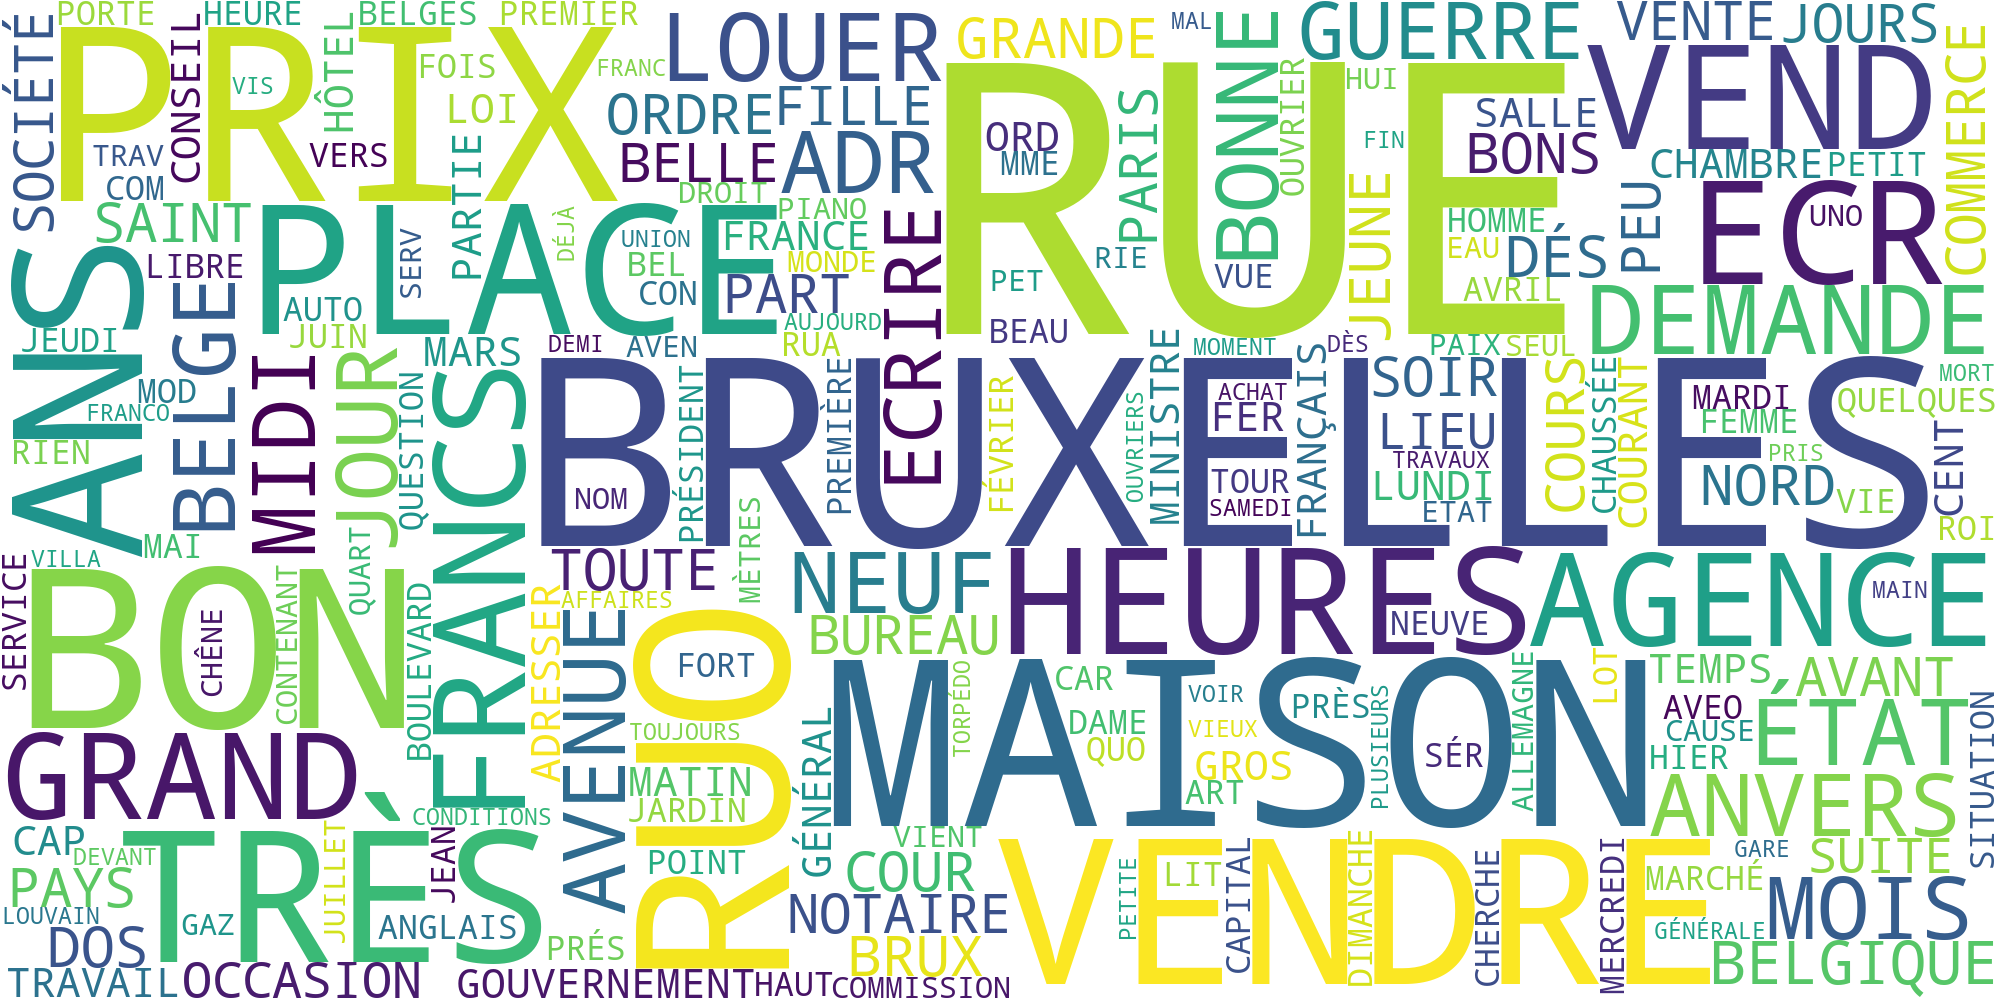

In [36]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))